# Astrometry

This section is a hands-on tutorial on how to make a simple run with joint RVs with astrometry (RV+AM).
We use the HIP 8923 data available on [GitHub](https://github.com/ReddTea/astroemperor/tree/main/docs/tutorials/datafiles/HIP8923).

## Data
We need to set up our working directory with two subfolders, `datafiles` and `datalogs`. 

`datafiles` will contain both our RV and AM catalogues. For each target or system we create a subfolder with the system name. In this case, `HIP8923`. Inside, we create two subfolders, one named `RV`, which will contain the RV data, and another named `AM`, containing the astrometry data.

We copy-paste the file downloaded from GitHub into `/datafiles/HIP8923`.


```
📂working_directory
 ┣ 📜mini_test.py
 ┣ 📂datafiles
 ┃ ┣ 📂HIP8923
 ┃ ┃ ┣ 📂RV
 ┃ ┃ ┃ ┣ 📜HIP8923_1_cor07.vels
 ┃ ┃ ┃ ┣ 📜HIP8923_2_cor14.vels
 ┃ ┃ ┃ ┣ 📜HIP8923_3_cor14T.vels
 ┃ ┃ ┗ 📂AM
 ┃ ┃   ┣ 📜HIP8923_gost.csv
 ┃ ┃   ┣ 📜HIP8923_hip2.abs
 ┃ ┃   ┗ 📜HIP8923_hipgaia.hg123
 ┣ 📂datalogs
 ┃ ┣ 📂HIP8923
 ┃ ┃ ┗ 📂run_1
```

## Setting up EMPEROR

Under our working directory, we create a python file named `hip8923_test`.
First, we import the library and start our simulation:


In [1]:
from IPython.display import Image

import astroemperor as emp
import numpy as np
import multiprocessing
np.random.seed(1234)


sim = emp.Simulation()
sim.cores__ = multiprocessing.cpu_count()

I couldnt grab the terminal size. Trying with pandas...
Terminal size with pandas successful!
                                                                                
                   ~~ Simulation Successfully Initialized ~~                    
                                                                                


### Setting the engine

For this example, we will use `reddemcee`, with 11 temperatures, 128 walkers, 2560 sweeps each of 1 step:

In [2]:
#ntemps, nwalkers, nsweeps, nsteps = 11, 128, 1000, 1
#ntemps, nwalkers, nsweeps, nsteps = 6, 128, 500, 1
ntemps, nwalkers, nsweeps, nsteps = 11, 128, 2560, 1

sim.set_engine('reddemcee')
sim.engine_config['setup'] = [ntemps, nwalkers, nsweeps, nsteps]

# Custom adaptation options for reddemcee engine
sim.engine_config['tsw_history'] = True
sim.engine_config['smd_history'] = True
sim.engine_config['adapt_tau'] = 100
sim.engine_config['adapt_nu'] = 1.0
sim.engine_config['adapt_mode'] = 'SAR'

# Manual ladder
sim.engine_config['betas'] = list(np.geomspace(1, 0.001, ntemps))
# sim.engine_config['betas'][-1] = 0  # Optionally, for exact evidence estimation

sim.run_config['burnin'] = 0.5  # its in niter

### Setting the model
We feed the name of the instruments (optional), as well as the starmass and starmass error to calculate the true-mass and semi-major axis. We add some boundaries to speed up the process:

In [3]:
sim.starmass = 	1.0086627  # 0.9686578 1.0486716  # FLAME
sim.starmass_err = 0.0400069
sim.instrument_names_RV = ['Cor07', 'Cor14', 'Cor14T']

# Model options
sim.jitter_prargs = [0, 5]  # Normal(0, 5)
sim.eccentricity_prargs = [0, 0.1]  # Normal(0, 0.1)
sim.acceleration = 0  # no linear trend


# Offsets and Jitters manual boundaries
for i in range(1, 4):
    sim.add_condition([f'Offset {i}', 'limits', [-50, 50]])
    sim.add_condition([f'Jitter {i}', 'limits', [1e-4, 15]])

# we constrain a bit the planetary parameters
sim.add_condition(['Period 1', 'limits', [4500, 5500]])
sim.add_condition(['Amplitude 1', 'limits', [40, 55]])
sim.add_condition(['Eccentricity 1', 'limits', [0, 0.1]])

#sim.add_condition(['Phase 1', 'limits', [np.pi, 2*np.pi]])

# We also constrain astrometric offsets
for offset in ['RA', 'DE', 'PLX', 'pm RA', 'pm DE']:
    sim.add_condition([f'Offset {offset}', 'limits', [-1, 1]])  # usually -10, 10

# Finally, we set some sensible priors for Hipparcos and Gaia
sim.add_condition(['Jitter Gaia', 'limits', [1, 5]])  # fractional jitter
sim.add_condition(['Jitter Gaia', 'prior', 'Normal'])
sim.add_condition(['Jitter Gaia', 'prargs', [1, 0.1]])

sim.add_condition(['Jitter Hipp', 'limits', [0, 5]])  # additive jitter


Initial positions are really helpful, specially in these short tests.

In [4]:
if True:
    sim.add_condition(['Period 1',          'init_pos', [5150, 5170]])
    sim.add_condition(['Amplitude 1',       'init_pos', [48, 51]])
    sim.add_condition(['Eccentricity 1',    'init_pos', [0.005, 0.014]])
    sim.add_condition(['Phase 1',           'init_pos', [4.9, 5.1]])
    sim.add_condition(['Longitude 1',       'init_pos', [0.9, 0.94]])


    sim.add_condition(['Inclination 1', 'init_pos', [0.545, 0.555]])
    sim.add_condition(['Omega 1',       'init_pos', [2.065, 2.074]])

    sim.add_condition(['Offset RA',     'init_pos', [0.694, 0.696]])
    sim.add_condition(['Offset DE',     'init_pos', [0.335, 0.345]])
    sim.add_condition(['Offset PLX',    'init_pos', [0.010, 0.014]])
    sim.add_condition(['Offset pm RA',  'init_pos', [0.20, 0.22]])
    sim.add_condition(['Offset pm DE',  'init_pos', [-0.258, -0.254]])

    sim.add_condition(['Jitter Gaia', 'init_pos', [1.00, 1.01]])  # 0.01
    sim.add_condition(['Jitter Hipp', 'init_pos', [0.86, 0.88]])  # 0.01

In [5]:
sim.plot_posteriors['temps'] = [0]
sim.plot_gaussian_mixtures['plot'] = False
sim.plot_trace['plot'] = False
sim.plot_histograms['plot'] = False

In [6]:
sim.load_data('HIP8923')  # folder read from /datafiles/
sim.autorun(1, 1)




Reading data from HIP8923_1_cor07.vels
Reading data from HIP8923_1_cor14.vels
Reading data from HIP8923_1_cor14T.vels




                                                                                


                              Offset block added, OffsetBlock


                              Jitter block added, JitterBlock


                              Keplerian block added, AstrometryKeplerianBlock 1


                              AstrometryOffset block added, AstrometryOffsetBlock


                              AstrometryJitter block added, AstrometryJitterBlock



Condition applied: Parameter Period 1 attribute limits set to [4500, 5500]

Condition applied: Parameter Period 1 attribute init_pos set to [5150, 5170]

Condition applied: Parameter Amplitude 1 attribute limits set to [40, 55]

Condition applied: Parameter Amplitude 1 attribute init_pos set to [48, 51]

Condition applied: Parameter Phase 1 attribute init_pos set to [4.9, 5.1]

Condition applied: Parameter Ecc

100%|██████████| 28160/28160 [04:30<00:00, 104.07it/s]


temp_script.py took 270.826 seconds
Autocorrelation tolerance=50 fails. Setting to 0.
                         Calculating Gaussian Mixtures                          


100%|██████████| 22/22 [00:05<00:00,  3.93it/s]



                                 ~~ Best Fit ~~                                 


Parameter           Value(max)  Range(±σ)               Prior               Limits
----------------  ------------  ----------------------  ------------------  --------------
Period 1              5047.1    [5019.757, 5215.019]    ~𝓤 (4500, 5500)     [4500, 5500]
Amplitude 1             49.237  [48.981, 53.338]        ~𝓤 (40, 55)         [40, 55]
Phase 1                  5.422  [4.915, 5.585]          ~𝓤 (0.0, 6.283)     [0, 6.283]
Eccentricity 1           0.027  [0, 0.03]               ~𝓝 (0.0, 0.1)       [0, 0.1]
Longitude 1              0.387  [0.003, 0.727]          ~𝓤 (0.0, 6.283)     [0, 6.283]
Inclination 1            0.416  [0.402, 0.446]          ~I (0.0, 3.142)     [0, 3.142]
Omega 1                  1.71   [1.709, 1.854]          ~𝓤 (0.0, 6.283)     [0, 6.283]

----------------  ------------  ----------------------  ------------------  --------------
Offset 1               -29.795  [-30.871, 

...



                             Plotting Beta Density                              


100%|██████████| 1/1 [00:00<00:00,  5.99it/s]




                           Plotting Temperature Rates                           


100%|██████████| 10/10 [00:01<00:00,  9.98it/s]




                           Plotting Astrometric Model                           
I couldnt grab the terminal size. Trying with pandas...
Terminal size with pandas successful!




Time Table
Time RUN                   : 00:04:34
Time POSTPROCESS           : 00:00:10
Time CALCULATE GM          : 00:00:05
Time plot_posteriors       : 00:00:14
Time plot_histograms       : 00:00:00
Time plot_keplerian_model  : 00:00:00
Time plot_betas            : 00:00:00
Time plot_beta_density     : 00:00:00
Time plot_rates            : 00:00:01
Time plot_trace            : 00:00:00
Time plot_astrometric_model: 00:00:02

(Past BIC) - (Present BIC) > 5

 BIC condition met!!
inf - 585.812 > 5


                                                                                
                              ~~ End of the Run ~~                              
                                                                                




We can also recompute evidences:

In [7]:
z_ti = np.round(sim.sampler.get_evidence_ti(discard=sim.reddemcee_discard)[:2], 3)
z_ss = np.round(sim.sampler.get_evidence_ss(discard=sim.reddemcee_discard), 3)
z_hy = np.round(sim.sampler.get_evidence_hybrid(discard=sim.reddemcee_discard), 3)

print(f'Thermodynamic Integration logZ = {z_ti[0]} ±{z_ti[1]}')
print(f'Stepping Stones logZ           = {z_ss[0]} ±{z_ss[1]}')
print(f'Hybrid Method logZ             = {z_hy[0]} ±{z_hy[1]}')

Thermodynamic Integration logZ = -296.86 ±2.289
Stepping Stones logZ           = -296.64 ±0.082
Hybrid Method logZ             = -296.705 ±2.376


Thermodynamic Integration logZ = -308.941 ±2.876

Stepping Stones logZ           = -308.473 ±0.497

Hybrid Method logZ             = -302.723 ±3.042

And visualise our results:

`Disclaimer: Longer chains should be used for reliable results.`

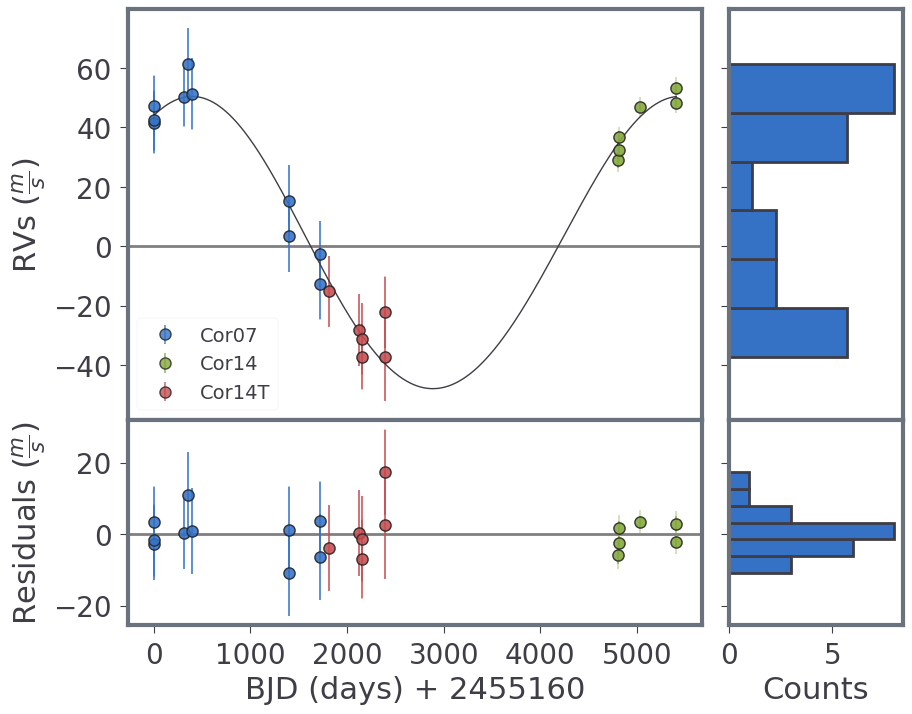

In [8]:
loc = sim.saveplace
Image(filename=f'{loc}/plots/models/KeplerianModel.png') 

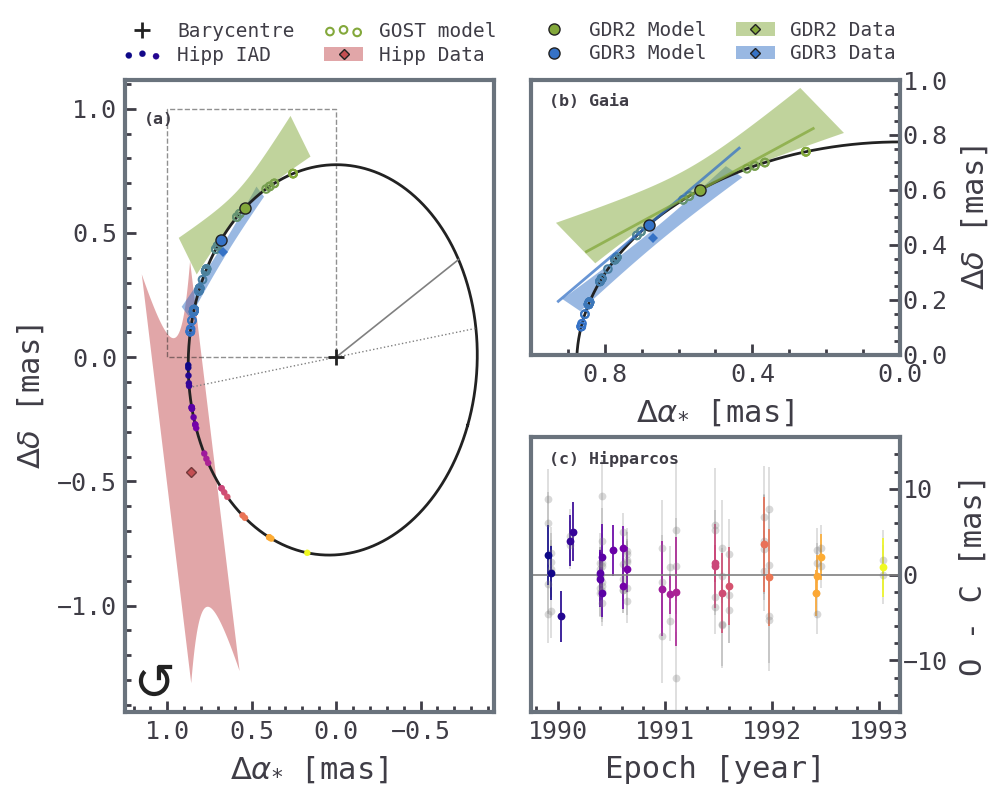

In [9]:
Image(filename=f'{loc}/plots/models/astrometry_model.png') 